# 01 · 真实行情入门：SPY、IEF、GLD 的收益与风险

**目标：**读懂真实行情，区分价格与总回报近似，计算复利收益、波动、回撤和相关性。

适合已有基础 Python／统计知识、正在学习金融的你。这里没有预测模型或自动交易；结果是历史描述，不是未来收益承诺。

顺序：读取快照 → 数据检查 → 价格与分红 → 收益风险 → 相关性 → 小练习。

数据源为 Yahoo Finance，经 yfinance 下载。研究区间从 2010 年起至 2026-10-06；截止日期由本次查询决定。

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "src/market_data.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "src/market_data.py").exists(), "请从项目根目录或 notebooks 目录运行"
os.environ["MPLCONFIGDIR"] = str(ROOT / ".cache/matplotlib")
sys.path.insert(0, str(ROOT / "src"))
import matplotlib.pyplot as plt
from market_data import load_snapshot, analyze
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.2})
print("项目解释器：", sys.executable)

项目解释器： PROJECT_ROOT/.venv/bin/python


## 1. 固定快照，保证结果可复现

这份 Notebook 默认读取本次保存的快照，不会在运行中悄悄更换数据。

以后更新：在项目根目录运行 `./.venv/bin/python src/market_data.py`；默认排除纽约当天日线。
然后将下面 `SNAPSHOT` 改为新快照编号，或设为 `None` 读取最新快照。每次下载保留旧文件。

校验值用于发现本地文件被改动，**不代表数据商的记录已经得到独立认证**。

In [2]:
SNAPSHOT = __import__('os').environ.get('MARKET_LAB_SNAPSHOT', '20261007T234808781424Z')  # 设为 None 时读取 latest.json 指向的快照
frames, manifest = load_snapshot(SNAPSHOT)
OUT = ROOT / "reports" / manifest["snapshot"]
OUT.mkdir(parents=True, exist_ok=True)
PROCESSED = ROOT / "data/processed" / manifest["snapshot"]
PROCESSED.mkdir(parents=True, exist_ok=True)
display(pd.Series({k: manifest[k] for k in ["source", "retrieved_at_utc", "start_inclusive", "end_exclusive", "snapshot"]}, name="Metadata"))

source                    Yahoo Finance via yfinance
retrieved_at_utc    2026-10-07T23:48:08.781424+00:00
start_inclusive                           2010-01-01
end_exclusive                             2026-10-07
snapshot                      20261007T234808781424Z
Name: Metadata, dtype: object

## 2. 检查完整性，不先填补缺失数据

SPY 表示美国大型股票，IEF 表示 7–10 年美国国债，GLD 表示黄金。

下面检查各自日期范围、缺失价格、分红记录，以及三只资产的日期是否对齐。只在共同有记录的日期上比较，不使用向前填充来制造零收益。

**检查边界：**跨资产对齐无法发现三者同时缺失的交易日；本阶段尚未与独立交易日历和第二行情源逐条核对。

In [3]:
audit = pd.DataFrame({s: {
    "rows": len(df), "first_date": str(df.index.min().date()),
    "last_date": str(df.index.max().date()),
    "duplicate_dates": int(df.index.duplicated().sum()),
    "missing_adjusted_close": int(df["Adj Close"].isna().sum()),
    "dividend_records": int((df["Dividends"] > 0).sum()),
} for s, df in frames.items()}).T
panel, prices, returns, nav, drawdown, stats = analyze(frames)
display(audit)
missing = panel.isna().sum().rename("Missing vs union of observed dates")
display(missing)
print("共同价格日期：", len(prices), "；收益观测：", len(returns))
print("未进入共同样本的日期数：", len(panel) - len(prices))
audit.to_csv(OUT / "data_audit.csv")
prices.to_parquet(PROCESSED / "adjusted_close.parquet")
returns.to_parquet(PROCESSED / "daily_returns.parquet")

,rows,first_date,last_date,duplicate_dates,missing_adjusted_close,dividend_records
SPY,4215,2010-01-04,2026-10-06,0,0,67
IEF,4215,2010-01-04,2026-10-06,0,0,201
GLD,4215,2010-01-04,2026-10-06,0,0,0


Asset
SPY    0
IEF    0
GLD    0
Name: Missing vs union of observed dates, dtype: int64

共同价格日期： 4215 ；收益观测： 4214
未进入共同样本的日期数： 0


## 3. Close 和 Adj Close 为什么不同？

`Close` 是数据商的收盘价字段；Yahoo 历史价格本身可能已处理拆股，并非逐笔原始成交记录。

`Adj Close` 进一步用于反映分红等调整。用其涨幅近似含分红再投资的总回报，不再把分红加一次。

ETF 分红后价格可能下降，若只看 Close，会把支付给持有人的现金漏掉。这里只作统一口径比较：不计个人税费、交易成本或再投资执行误差；基金费用已体现在基金表现里，不再重复扣除。

In [4]:
price_only = pd.DataFrame({s: df["Close"] for s, df in frames.items()}).loc[prices.index]
comparison = pd.DataFrame({
    "Close change": price_only.iloc[-1] / price_only.iloc[0] - 1,
    "Adjusted total-return proxy": nav.iloc[-1] - 1,
})
display(comparison.style.format("{:.2%}"))
display(frames["IEF"].loc[lambda x: x["Dividends"] > 0, ["Close", "Adj Close", "Dividends"]].tail(3))
comparison.to_csv(OUT / "price_vs_adjusted_return.csv")

,Close change,Adjusted total-return proxy
SPY,587.45%,823.43%
IEF,0.35%,47.31%
GLD,248.15%,248.15%


,Close,Adj Close,Dividends
Date,,,
2026-08-03,92.820000,92.169785,0.318
2026-09-01,92.099998,91.783409,0.332
2026-10-01,89.300003,89.300003,0.307


## 4. 收益是连乘，不是相加

日收益：$r_t=P_t/P_{t-1}-1$。

净值：$V_t=\prod_{s=1}^{t}(1+r_s)$，起始值设为 1。

先检查用收益连乘重建的净值与价格归一化一致，再画图。下图是各资产分别持有的历史表现，还不是混合组合。

Asset,SPY,IEF,GLD
Date,,,
2010-01-05 00:00:00,0.265%,0.439%,-0.091%
2010-01-06 00:00:00,0.070%,-0.404%,1.650%
2010-01-07 00:00:00,0.422%,0.000%,-0.619%


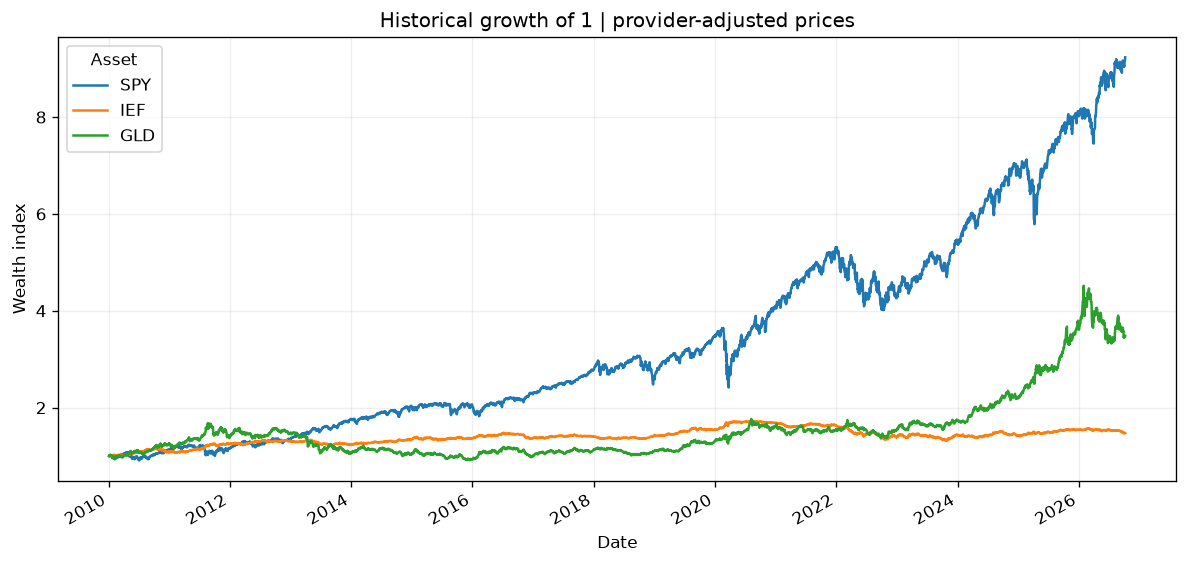

In [5]:
rebuilt = (1 + returns).cumprod()
np.testing.assert_allclose(rebuilt.to_numpy(), nav.iloc[1:].to_numpy(), rtol=1e-10)
display(returns.head(3).style.format("{:.3%}"))
fig, ax = plt.subplots(figsize=(10, 4.8))
nav.plot(ax=ax, linewidth=1.5)
ax.set(title="Historical growth of 1 | provider-adjusted prices", ylabel="Wealth index", xlabel="Date")
fig.tight_layout()
fig.savefig(OUT / "01_growth.png")
plt.show()

## 5. 收益与风险必须一起看

- 累计收益：最终净值减 1。
- CAGR：用实际日历年数计算的复合年增长率，不是每年稳定赚到这个比例。
- 年化波动：日收益样本标准差 × $\sqrt{252}$，252 是常用近似。
- 回撤：$V_t/\max_{s\le t}V_s-1$；最大回撤是样本内最深的一次。

这些指标对起止日期敏感，最大回撤也不是未来最大损失上限。

,Total return,CAGR,Annual volatility,Max drawdown
Asset,,,,
SPY,823.43%,14.19%,17.04%,-33.72%
IEF,47.31%,2.34%,6.57%,-23.92%
GLD,248.15%,7.73%,16.78%,-45.56%


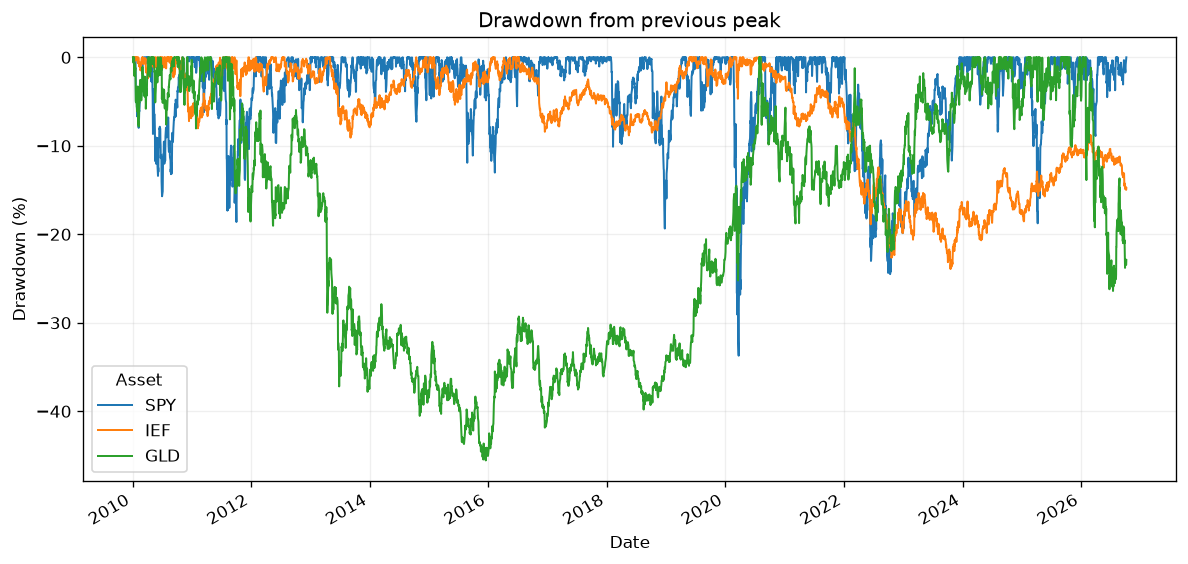

In [6]:
display(stats.style.format("{:.2%}"))
stats.to_csv(OUT / "metrics.csv")
fig, ax = plt.subplots(figsize=(10, 4.8))
(drawdown * 100).plot(ax=ax, linewidth=1.2)
ax.set(title="Drawdown from previous peak", ylabel="Drawdown (%)", xlabel="Date")
fig.tight_layout()
fig.savefig(OUT / "02_drawdown.png")
plt.show()

## 6. 相关性会变化：债券不总与股票反向

全样本相关性概括整个区间，滚动相关性观察最近约一年（252 条日收益）。计算使用收益率而非价格水平。

相关性反映共同变化，不证明因果。整体相关性较低，也不能保证最需要保护的时刻一定有效。

Asset,SPY,IEF,GLD
Asset,,,
SPY,1.000,-0.247,0.072
IEF,-0.247,1.000,0.277
GLD,0.072,0.277,1.000


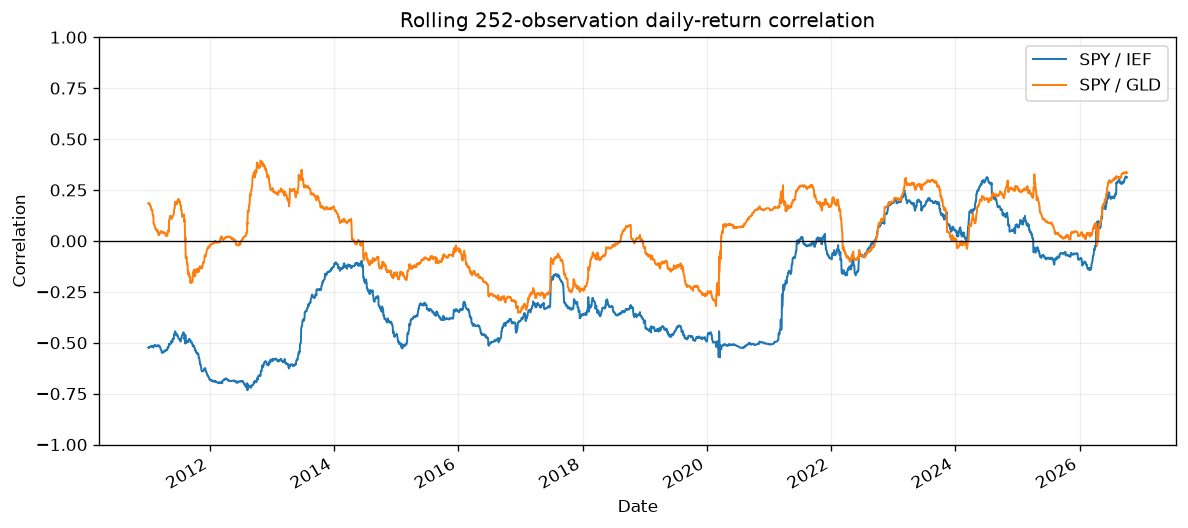

In [7]:
corr = returns.corr()
display(corr.style.format("{:.3f}"))
corr.to_csv(OUT / "return_correlations.csv")
rolling = pd.DataFrame({
    "SPY / IEF": returns["SPY"].rolling(252).corr(returns["IEF"]),
    "SPY / GLD": returns["SPY"].rolling(252).corr(returns["GLD"]),
})
fig, ax = plt.subplots(figsize=(10, 4.5))
rolling.plot(ax=ax, linewidth=1.2)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Rolling 252-observation daily-return correlation", ylabel="Correlation", ylim=(-1, 1), xlabel="Date")
fig.tight_layout()
fig.savefig(OUT / "03_rolling_correlation.png")
plt.show()

## 7. 看年度变化，而不是只看一条长期曲线

每年收益由该年日收益连乘得到。第一年是自首个样本收盘后开始，最后一年通常只是年初至今；不能把最后一行当作全年预测。

In [8]:
annual = (1 + returns).resample("YE").prod() - 1
annual.index = annual.index.year
annual.index.name = "Year (first/last may be partial)"
display(annual.tail(7).style.format("{:.2%}"))
annual.to_csv(OUT / "calendar_year_returns.csv")
summary = {
    "snapshot": manifest["snapshot"], "first_date": str(prices.index[0].date()),
    "last_date": str(prices.index[-1].date()), "price_rows": len(prices),
    "return_rows": len(returns), "metrics": stats.to_dict(orient="index"),
    "correlations": corr.to_dict(), "latest_rolling_correlation": rolling.iloc[-1].to_dict(),
    "price_vs_adjusted": comparison.to_dict(orient="index"),
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("结果已保存：", OUT)

Asset,SPY,IEF,GLD
Year (first/last may be partial),,,
2020,18.33%,10.01%,24.81%
2021,28.73%,-3.33%,-4.15%
2022,-18.18%,-15.16%,-0.77%
2023,26.18%,3.64%,12.69%
2024,24.89%,-0.63%,26.66%
2025,17.72%,8.03%,63.68%
2026,15.14%,-4.50%,-3.54%


结果已保存： PROJECT_ROOT/reports/20261007T234808781424Z


## 8. 小练习：亏损后涨回来，需要多少？

如果净值从 1 跌到 0.8，随后上涨 20%，是否回到 1？请先心算，再运行下一格。

延伸练习：比较 2022 年 SPY、IEF、GLD 的表现，看看“债券永远能对冲股票”是否成立。这个观察只用于理解历史；事后挑选一个年份不构成可交易策略。

In [9]:
after_fall = 1 * (1 - 0.20)
after_rebound = after_fall * (1 + 0.20)
required_gain = 1 / after_fall - 1
print(f"跌20%再涨20%后的净值：{after_rebound:.2f}")
print(f"从0.8回到1需要上涨：{required_gain:.1%}")
if 2022 in annual.index:
    display(annual.loc[[2022]].style.format("{:.2%}"))

跌20%再涨20%后的净值：0.96
从0.8回到1需要上涨：25.0%


Asset,SPY,IEF,GLD
Year (first/last may be partial),,,
2022,-18.18%,-15.16%,-0.77%


## 接下来做什么？

先能解释上面三张图和三种口径：价格／含分红回报近似、累计／年化收益、波动／回撤。

下一份 Notebook 才比较固定股债配置与等权组合，明确权重漂移、调仓时间和交易成本。

参考：[yfinance](https://github.com/ranaroussi/yfinance) · [SPY](https://www.ssga.com/us/en/individual/etfs/state-street-spdr-sp-500-etf-trust-spy) · [IEF](https://www.ishares.com/us/products/239456/ishares-710-year-treasury-bond-etf) · [GLD](https://www.spdrgoldshares.com/usa/gld/)

数据是本次下载时数据商提供的历史版本，可能包含事后修订。它足以开始描述性研究，但不能直接宣称为完全按历史当时信息构建的策略回测。